# Staggered Adoption — State Minimum-Wage Increases and Food-Service Employment

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** BLS QCEW, 2014 Q1 to 2023 Q4 (each quarter a separate file; the Bureau revises, so this is the retrieval, not a pinned vintage)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a
retrieval fails, a cell is withheld in a way the plan did not allow for, or a check stops, the
notebook stops.

The analysis was fixed in a **pre-analysis plan** (`pap/C03_pap.md`) committed before any table here
was retrieved. The notebook is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** why a two-way fixed-effects regression with staggered treatment timing compares some
   units to others that are *already treated*, and what that does to the estimate.
2. **Decompose** a two-way fixed-effects estimate into its two-by-two comparisons and read the weights.
3. **Estimate** an effect with an interaction-weighted event-study estimator that never uses an
   already-treated unit as a control.
4. **Check** that estimator against a second one built on different controls (never-treated and
   not-yet-treated), and apply a decision rule written before the data were seen.
5. **Say, from computed numbers and not from prose,** whether the naive estimate and the robust one
   disagree in sign.

## Prerequisites

**Knowledge.** Two-way fixed effects; the difference-in-differences estimand (see C01); what a
cluster-robust standard error is for.

**Setup.** No API key is needed: the QCEW files are open. The retrieval makes 40 requests of about
0.8 MB each and takes several minutes; the Bureau sometimes answers HTTP 503 to a burst, and the
cell waits and retries only on that status.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, and the local `krl_tutorials_data` package
(its `methods.did` module holds the estimators).

**Prior notebooks.** C01 introduces the identification contract and the two-by-two.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| QCEW industry slice, NAICS 722, county level, private ownership | BLS Quarterly Census of Employment and Wages, one file per quarter | outcome: log of mean monthly employment |
| `data/policy/minimum_wage/state_schedule.csv` | U.S. Department of Labor, January-1 state minimum wages | treatment timing |

Each quarter's request is recorded in `provenance/`, bound to the plan's SHA-256. A QCEW cell is
**withheld** when publishing it could identify an employer, and the Bureau publishes the withheld
values as zeros; the client converts them to missing before any arithmetic. The Bureau serves its
slices from 2014 Q1, so the window is 2014–2023, not the track's 2012–2023; the plan records this.

## Design and identification

**Estimand.** The average effect, over the first twelve quarters after a state's minimum wage first
exceeds the federal minimum, on county private employment in food services and drinking places, in
log points, averaged over adopting cohorts.

**Assumption.** Parallel trends in the absence of the increase, between each adopting cohort and the
counties used as its control. With staggered timing the assumption has to hold for *every* comparison
the estimator makes, which is why the choice of comparison matters.

**Decision rule, fixed in the plan.** No effect if the 95% interval of the headline estimate contains
zero. Credible only if both falsifications pass; otherwise the estimates are descriptive.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import did
from krl_tutorials_data.provenance import DataProvenance
from krl_tutorials_data.sources import DataAccessError, UpstreamError, fetch_qcew

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C03_minimum_wage_staggered"
PAP = NB_DIR / "pap" / "C03_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

FIRST_YEAR, LAST_YEAR = 2014, 2023
QUARTERS = [(y, q) for y in range(FIRST_YEAR, LAST_YEAR + 1) for q in (1, 2, 3, 4)]
FEDERAL = 7.25
LEADS, POST_QUARTERS = 4, 12          # event window: -4 and earlier binned; headline = e 0..11
N_BOOT, SEED = 999, 20261022

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"window            : {FIRST_YEAR}Q1-{LAST_YEAR}Q4, {len(QUARTERS)} quarters")

pre-analysis plan : projects/09-causal-identification/C03_minimum_wage_staggered/pap/C03_pap.md
plan SHA-256      : 65be61d3db840e93d8dc6241defe80b10e772d40c2c2c4735e38d6c7d3831f22
window            : 2014Q1-2023Q4, 40 quarters


### Retrieving the quarterly files

One request per quarter for NAICS 722 in every county. The cell waits and retries only on HTTP 503,
which the Bureau uses to slow a burst; any other failure stops the notebook.

In [2]:
def get_slice(year: int, quarter: int):
    """One quarter's industry slice, retrying only a 503 with a growing pause."""
    for pause in (0, 5, 15, 45, 90):
        clock.sleep(pause)
        try:
            return fetch_qcew(year=year, quarter=quarter, industry="722", contact="research")
        except UpstreamError as exc:
            if "HTTP 503" not in str(exc):
                raise
    raise UpstreamError(f"QCEW kept answering 503 for {year} Q{quarter}")


parts, records, withheld_rows = [], [], 0
try:
    for year, quarter in QUARTERS:
        frame, prov = get_slice(year, quarter)
        county = frame[(frame["own_code"] == "5") & (frame["agglvl_code"] == "75")].copy()
        county["year"], county["quarter"] = year, quarter
        parts.append(county[["area_fips", "year", "quarter", "month1_emplvl", "month2_emplvl",
                             "month3_emplvl", "suppressed"]])
        withheld_rows += int(county["suppressed"].sum())
        prov.with_pap(PAP).write(NB_DIR / "provenance" / f"c03_qcew_722_{year}q{quarter}.json")
        records.append(prov)
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

raw = pd.concat(parts, ignore_index=True)
print(f"quarters retrieved : {len(records)}; county-quarter rows: {len(raw):,}")
print(f"withheld rows      : {withheld_rows:,} ({withheld_rows / len(raw):.1%})")
print(records[0].render())

quarters retrieved : 40; county-quarter rows: 130,072
withheld rows      : 24,723 (19.0%)
Source      : U.S. Bureau of Labor Statistics - QCEW industry 722, 2014 Q1
Vintage     : 2014Q1  (NOT pinned - the source serves no prior vintage; this retrieval is the only one)
Endpoint    : https://data.bls.gov/cew/data/api/2014/1/industry/722.csv
Retrieved   : 2026-10-22T18:39:47+00:00
Shape       : 4166 rows x 43 cols
Payload hash: 36e56d65049d7ef4...  (response-bytes)
Data mode   : EMPIRICAL
Variables   :
              qtrly_estabs     QCEW field
              month1_emplvl    QCEW field
              month2_emplvl    QCEW field
              month3_emplvl    QCEW field
              total_qtrly_wages QCEW field
              taxable_qtrly_wages QCEW field
              qtrly_contributions QCEW field
              avg_wkly_wage    QCEW field
Limitations :
              - 934 of 4166 rows carry disclosure_code 'N' (withheld to protect employer identity).
              - 6538 withheld values w

In [3]:
"""Classify every state from the DOL schedule, as the plan defines."""
schedule = pd.read_csv(REPO_ROOT / "data" / "policy" / "minimum_wage" / "state_schedule.csv")
TERRITORIES = {"Guam", "Puerto Rico", "U.S. Virgin Islands", "Virgin Islands"}
window = schedule[(schedule["year"] >= FIRST_YEAR) & (schedule["year"] <= LAST_YEAR)
                  & (schedule["jurisdiction"] != "Federal (FLSA)")
                  & (~schedule["jurisdiction"].isin(TERRITORIES))]
federal_rows = schedule[(schedule["jurisdiction"] == "Federal (FLSA)") & schedule["year"].between(FIRST_YEAR, LAST_YEAR)]
assert (federal_rows["rate_low"] == FEDERAL).all(), "the federal rate must be constant over the window"

first_above = {}
for state, rows in window.groupby("jurisdiction"):
    above = rows[rows["rate_low"].fillna(0) > FEDERAL]["year"]
    first_above[state] = int(above.min()) if len(above) else None

classes = pd.Series({s: ("treated throughout" if y == FIRST_YEAR else "never treated" if y is None else "adopter")
                     for s, y in first_above.items()})
print(classes.value_counts().to_string())
print("adopters by first year above federal:",
      sorted((y, sum(v == y for v in first_above.values())) for y in set(first_above.values()) if y and y > FIRST_YEAR))
assert len(first_above) == 51, "expected the 50 states and the District of Columbia"

treated throughout    21
never treated         20
adopter               10
adopters by first year above federal: [(2015, 6), (2017, 2), (2020, 1), (2021, 1)]


In [4]:
"""State names for the two-digit codes, from the Census Bureau's own reference file."""
FIPS_URL = "https://www2.census.gov/geo/docs/reference/state.txt"
reply = requests.get(FIPS_URL, timeout=60, headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
codes = pd.read_csv(io.StringIO(reply.text), sep="|", dtype=str)
state_name = dict(zip(codes["STATE"], codes["STATE_NAME"]))
DataProvenance.build(
    pinned=False, source_name="U.S. Census Bureau", dataset="State FIPS codes and names",
    vintage="retrieval", endpoint=FIPS_URL, variables={"STATE": "FIPS code", "STATE_NAME": "name"},
    payload=reply.content, row_count=len(codes), column_count=len(codes.columns),
    notes=("A reference list used only to attach state names to county codes.",),
).with_pap(PAP).write(NB_DIR / "provenance" / "c03_state_fips.json")
print(f"state codes read: {len(codes)}")

state codes read: 57


In [5]:
"""County panel: log mean monthly employment, balanced, with the coverage that costs."""
raw["area_fips"] = raw["area_fips"].astype(str).str.zfill(5)
raw["t"] = 4 * (raw["year"] - FIRST_YEAR) + (raw["quarter"] - 1)
raw["emp"] = raw[["month1_emplvl", "month2_emplvl", "month3_emplvl"]].mean(axis=1, skipna=False)
raw["state"] = raw["area_fips"].str[:2].map(state_name)
raw = raw[raw["state"].isin(first_above)].copy()
raw["usable"] = (~raw["suppressed"]) & (raw["emp"] > 0)

per_county = raw.groupby("area_fips")["usable"].sum()
keep = per_county[per_county == len(QUARTERS)].index
first_q = raw[raw["t"] == 0]
share_emp = first_q[first_q["area_fips"].isin(keep)]["emp"].sum() / first_q[first_q["usable"]]["emp"].sum()
print(f"counties with any row     : {per_county.size:,}")
print(f"counties usable in all {len(QUARTERS)} quarters: {keep.size:,} ({keep.size / per_county.size:.1%})")
print(f"their share of 2014 Q1 employment among disclosed counties: {share_emp:.1%}")

panel = raw[raw["area_fips"].isin(keep)].sort_values(["area_fips", "t"]).reset_index(drop=True)
panel["lnemp"] = np.log(panel["emp"])
panel["class"] = panel["state"].map(classes)
cohort_q = {s: (np.nan if y is None else 0 if y == FIRST_YEAR else 4 * (y - FIRST_YEAR)) for s, y in first_above.items()}
panel["cohort"] = panel["state"].map(cohort_q)
panel["D"] = (panel["t"] >= panel["cohort"].fillna(np.inf)).astype(float)
by_class = panel.drop_duplicates("area_fips").groupby("class").agg(counties=("area_fips", "size"), states=("state", "nunique"))
print(by_class.to_string())

counties with any row     : 3,187
counties usable in all 40 quarters: 1,841 (57.8%)
their share of 2014 Q1 employment among disclosed counties: 95.7%
                    counties  states
class                               
adopter                  337      10
never treated            929      20
treated throughout       575      21


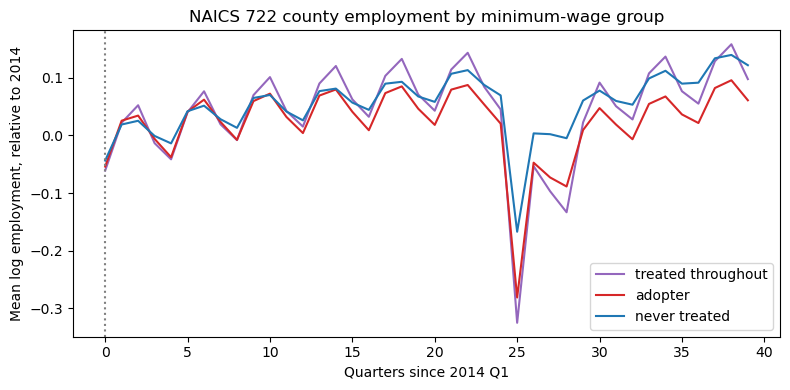

In [6]:
"""The raw picture: mean log employment by group, each relative to its 2014 average."""
means = panel.groupby(["t", "class"])["lnemp"].mean().unstack("class")
means = means - means.loc[0:3].mean()
fig, ax = plt.subplots(figsize=(8, 4))
for name, colour in (("treated throughout", "tab:purple"), ("adopter", "tab:red"), ("never treated", "tab:blue")):
    ax.plot(means.index, means[name], color=colour, label=name)
ax.axvline(0, color="grey", linestyle=":")
ax.set_xlabel("Quarters since 2014 Q1")
ax.set_ylabel("Mean log employment, relative to 2014")
ax.set_title("NAICS 722 county employment by minimum-wage group")
ax.legend()
plt.tight_layout()
plt.show()

### Estimate 1: the naive two-way fixed-effects regression

One treatment dummy, county and quarter fixed effects, all three groups in the sample. This is the
regression most people would run first.

In [7]:
"""Naive TWFE on the full balanced panel."""
y = panel["lnemp"].to_numpy()
unit, tq = panel["area_fips"].to_numpy(), panel["t"].to_numpy()
state = panel["state"].to_numpy()
naive = did.twfe(y, panel[["D"]].to_numpy(dtype=float), unit, tq, cluster=state)
b_naive, se_naive = float(naive.coef[0]), float(naive.se[0])
t_crit = float(stats.t.ppf(0.975, naive.n_clusters - 1))
print(f"counties / quarters / rows : {naive.n_units:,} / {naive.n_periods} / {naive.n_obs:,}")
print(f"naive TWFE estimate        : {b_naive:+.4f} log points (SE {se_naive:.4f}, {naive.n_clusters} state clusters)")
print(f"95% interval               : [{b_naive - t_crit * se_naive:+.4f}, {b_naive + t_crit * se_naive:+.4f}]")

counties / quarters / rows : 1,841 / 40 / 73,640
naive TWFE estimate        : -0.0250 log points (SE 0.0133, 51 state clusters)
95% interval               : [-0.0516, +0.0017]


### Estimate 2: what that regression is averaging

The Goodman-Bacon decomposition rebuilds the estimate above from every two-by-two comparison it
makes, with the weight each one carries. A comparison in which a *later*-treated group is compared
with an *earlier*-treated group that is already treated uses a treated unit as the control; those are
the comparisons that can pull the estimate the wrong way when effects change over time.

decomposition rebuilds the naive estimate: -0.0250
number of two-by-two comparisons: 20
      comparison  weight  weighted mean estimate
treated vs never  0.5644                 -0.0334
earlier vs later  0.0239                 -0.0084
later vs earlier  0.4117                 -0.0143


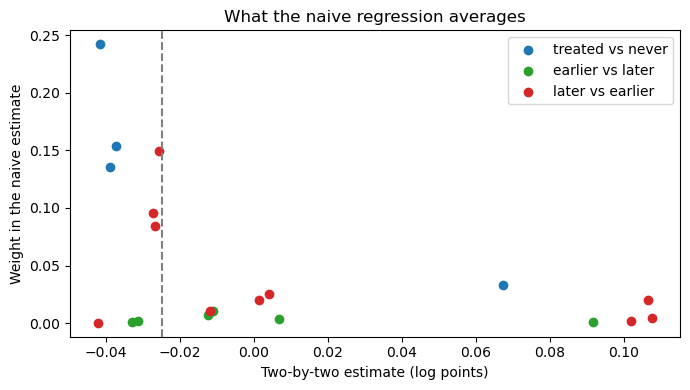

In [8]:
"""Decompose the naive estimate."""
dec = did.bacon_decomposition(y, unit, tq, panel["cohort"].to_numpy())
assert abs(dec.twfe - b_naive) < 1e-8
kinds = dec.by_kind()
table = pd.DataFrame(
    [{"comparison": k.replace("_", " "), "weight": w, "weighted mean estimate": m} for k, (w, m) in kinds.items()]
)
print(f"decomposition rebuilds the naive estimate: {dec.twfe:+.4f}")
print(f"number of two-by-two comparisons: {len(dec.comparisons)}")
print(table.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
for kind, colour in (("treated_vs_never", "tab:blue"), ("earlier_vs_later", "tab:green"), ("later_vs_earlier", "tab:red")):
    pts = [(c.estimate, c.weight) for c in dec.comparisons if c.kind == kind]
    if pts:
        ax.scatter([p[0] for p in pts], [p[1] for p in pts], color=colour, label=kind.replace("_", " "))
ax.axvline(b_naive, color="grey", linestyle="--")
ax.set_xlabel("Two-by-two estimate (log points)")
ax.set_ylabel("Weight in the naive estimate")
ax.set_title("What the naive regression averages")
ax.legend()
plt.tight_layout()
plt.show()

### Estimate 3: an interaction-weighted event study that never uses a treated unit as a control

The treated-throughout states have no pre-period, so they are set aside here. Each adopting cohort is
compared with never-treated counties, event time by event time, and the cohort-specific effects are
averaged with weights equal to each cohort's share. The headline is the mean effect over the first
twelve quarters.

cohorts (first treated quarter): [4, 12, 24, 28]; states clustered: 30
headline, mean ATT over event times 0-11: -0.0000 (SE 0.0052), 95% interval [-0.0107, +0.0106]


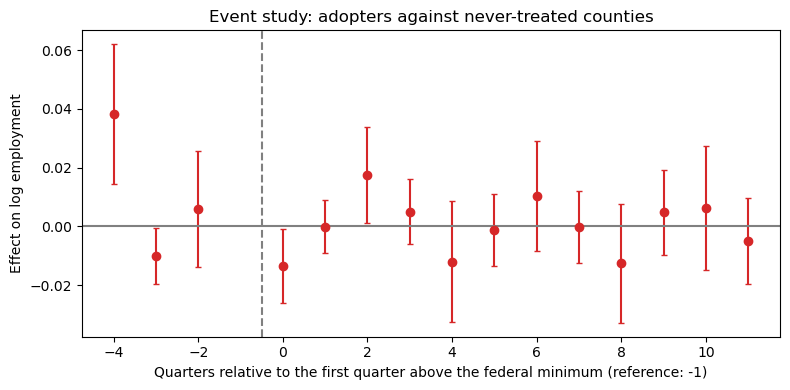

In [9]:
"""Sun-Abraham interaction-weighted estimator on adopters and never-treated counties."""
sub = panel[panel["class"] != "treated throughout"]
sa = did.sun_abraham(
    sub["lnemp"].to_numpy(), sub["area_fips"].to_numpy(), sub["t"].to_numpy(),
    sub["cohort"].to_numpy(), leads=LEADS, lags=int(sub["t"].max()), cluster=sub["state"].to_numpy(),
)
ev = np.array(sa.event_times)
post_mask = (ev >= 0) & (ev < POST_QUARTERS)
w_head = post_mask / post_mask.sum()
b_sa = float(w_head @ sa.att)
se_sa = float(np.sqrt(w_head @ sa.vcov @ w_head))
t_sa = float(stats.t.ppf(0.975, sa.n_clusters - 1))
ci_sa = (b_sa - t_sa * se_sa, b_sa + t_sa * se_sa)
print(f"cohorts (first treated quarter): {[int(c) for c in sa.cohorts]}; states clustered: {sa.n_clusters}")
print(f"headline, mean ATT over event times 0-{POST_QUARTERS - 1}: {b_sa:+.4f} (SE {se_sa:.4f}), 95% interval [{ci_sa[0]:+.4f}, {ci_sa[1]:+.4f}]")

shown = (ev >= -LEADS) & (ev < POST_QUARTERS)
half = t_sa * sa.se
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ev[shown], sa.att[shown], yerr=half[shown], fmt="o", color="tab:red", capsize=2)
ax.axhline(0, color="grey")
ax.axvline(-0.5, color="grey", linestyle="--")
ax.set_xlabel("Quarters relative to the first quarter above the federal minimum (reference: -1)")
ax.set_ylabel("Effect on log employment")
ax.set_title("Event study: adopters against never-treated counties")
plt.tight_layout()
plt.show()

In [10]:
"""Falsification 1: the pre-period coefficients are jointly zero."""
pre_idx = [list(ev).index(e) for e in (-4, -3, -2)]
b_pre = sa.att[pre_idx]
v_pre = sa.vcov[np.ix_(pre_idx, pre_idx)]
wald = float(b_pre @ np.linalg.solve(v_pre, b_pre))
f_pre = wald / len(pre_idx)
p_pre = float(stats.f.sf(f_pre, len(pre_idx), sa.n_clusters - 1))
PRE_PASS = p_pre >= 0.10
print(f"FALSIFICATION: pre-period event-time coefficients -4..-2 jointly zero | statistic={f_pre:.3f} | F({len(pre_idx)},{sa.n_clusters - 1}) p={p_pre:.4f}, threshold 0.10 | verdict={'PASS' if PRE_PASS else 'FAIL'}")

FALSIFICATION: pre-period event-time coefficients -4..-2 jointly zero | statistic=5.489 | F(3,29) p=0.0041, threshold 0.10 | verdict=FAIL


In [11]:
"""What the pre-period test is looking at."""
leads_table = pd.DataFrame({"event time": [-4, -3, -2], "coefficient": b_pre, "se": sa.se[pre_idx]})
leads_table["t"] = leads_table["coefficient"] / leads_table["se"]
print(leads_table.round(4).to_string(index=False))
largest = leads_table.loc[leads_table["t"].abs().idxmax()]
print(f"Largest lead: event time {int(largest['event time'])}, {largest['coefficient']:+.4f} log points (t = {largest['t']:+.2f}).")
print(f"Headline effect for comparison: {b_sa:+.4f} log points. A lead of that size before adoption "
      f"{'is larger than' if abs(largest['coefficient']) > abs(b_sa) else 'is smaller than'} the headline effect.")

 event time  coefficient     se       t
         -4       0.0383 0.0116  3.3029
         -3      -0.0101 0.0047 -2.1627
         -2       0.0059 0.0097  0.6125
Largest lead: event time -4, +0.0383 log points (t = +3.30).
Headline effect for comparison: -0.0000 log points. A lead of that size before adoption is larger than the headline effect.


In [12]:
"""Falsification 2: never-treated and not-yet-treated controls give the same answer."""
cs = {}
for control in ("never", "not_yet"):
    cs[control] = did.group_time_att(
        sub["lnemp"].to_numpy(), sub["area_fips"].to_numpy(), sub["t"].to_numpy(), sub["cohort"].to_numpy(),
        leads=LEADS, lags=POST_QUARTERS - 1, control=control, n_boot=N_BOOT, seed=SEED,
        cluster=sub["state"].to_numpy(),
    )
    fit = cs[control]
    print(f"{control:8s} controls: overall ATT {fit.overall:+.4f}, bootstrap SE {fit.overall_se:.4f}, 95% interval [{fit.overall_ci[0]:+.4f}, {fit.overall_ci[1]:+.4f}]")
gap = cs["never"].overall - cs["not_yet"].overall
slack = max(cs["never"].overall_se, cs["not_yet"].overall_se)
AGREE_PASS = abs(gap) <= slack
print(f"FALSIFICATION: never-treated versus not-yet-treated controls | statistic={gap:.4f} | difference in overall ATT, larger bootstrap SE {slack:.4f} | verdict={'PASS' if AGREE_PASS else 'FAIL'}")

never    controls: overall ATT -0.0002, bootstrap SE 0.0075, 95% interval [-0.0151, +0.0133]


not_yet  controls: overall ATT +0.0001, bootstrap SE 0.0075, 95% interval [-0.0151, +0.0131]
FALSIFICATION: never-treated versus not-yet-treated controls | statistic=-0.0003 | difference in overall ATT, larger bootstrap SE 0.0075 | verdict=PASS


In [13]:
"""The three estimates side by side, and the sign statement computed from them."""
side = pd.DataFrame([
    {"estimate": "naive TWFE (all groups)", "log points": b_naive, "se": se_naive,
     "lo": b_naive - t_crit * se_naive, "hi": b_naive + t_crit * se_naive},
    {"estimate": "Sun-Abraham, never-treated controls", "log points": b_sa, "se": se_sa, "lo": ci_sa[0], "hi": ci_sa[1]},
    {"estimate": "group-time, never-treated controls", "log points": cs["never"].overall, "se": cs["never"].overall_se,
     "lo": cs["never"].overall_ci[0], "hi": cs["never"].overall_ci[1]},
    {"estimate": "group-time, not-yet-treated controls", "log points": cs["not_yet"].overall, "se": cs["not_yet"].overall_se,
     "lo": cs["not_yet"].overall_ci[0], "hi": cs["not_yet"].overall_ci[1]},
])
print(side.round(4).to_string(index=False))
print()
w_fb, m_fb = kinds["later_vs_earlier"]
print(f"Weight on comparisons that use an already-treated group as the control: {w_fb:.1%} (their mean estimate {m_fb:+.4f}).")
differ = np.sign(b_naive) != np.sign(b_sa)
print(f"The naive and the interaction-weighted estimates have {'opposite' if differ else 'the same'} sign "
      f"({b_naive:+.4f} against {b_sa:+.4f}).")
inside = ci_sa[0] <= b_naive <= ci_sa[1]
print(f"The naive estimate lies {'inside' if inside else 'outside'} the 95% interval of the interaction-weighted one.")
null = ci_sa[0] <= 0.0 <= ci_sa[1]
print(f"Interval of the headline estimate contains zero (null by the plan's rule): {null}.")
print(f"Pre-period test passed: {PRE_PASS}; control-group agreement passed: {AGREE_PASS}.")
print("Both falsifications pass: by the plan's rule the estimates are credible for adopters 2015-2023."
      if PRE_PASS and AGREE_PASS else
      "At least one falsification fails: by the plan's rule the estimates are descriptive, not identified effects.")

                            estimate  log points     se      lo     hi
             naive TWFE (all groups)     -0.0250 0.0133 -0.0516 0.0017
 Sun-Abraham, never-treated controls     -0.0000 0.0052 -0.0107 0.0106
  group-time, never-treated controls     -0.0002 0.0075 -0.0151 0.0133
group-time, not-yet-treated controls      0.0001 0.0075 -0.0151 0.0131

Weight on comparisons that use an already-treated group as the control: 41.2% (their mean estimate -0.0143).
The naive and the interaction-weighted estimates have the same sign (-0.0250 against -0.0000).
The naive estimate lies outside the 95% interval of the interaction-weighted one.
Interval of the headline estimate contains zero (null by the plan's rule): True.
Pre-period test passed: False; control-group agreement passed: True.
At least one falsification fails: by the plan's rule the estimates are descriptive, not identified effects.


## Limitations

- **Suppressed county cells.** The balanced-panel rule drops every county with a withheld or zero cell in
  any quarter, and withholding is not random: it is applied where few establishments make a cell
  identifying. The retrieval and panel cells print how many counties and how much employment that costs;
  the estimates speak to the counties that remain.
- **Window.** The BLS slice API starts in 2014 Q1, so no state has a pre-period before 2014 and the
  states already above the federal minimum in 2014 have none at all. They are in the naive regression and
  its decomposition and absent from the interaction-weighted estimate, which therefore speaks only to
  adopters from 2015 to 2023.
- **Dating.** The schedule records January-1 values, so an increase made part-way through a year is dated to
  the next 1 January: up to two quarters of treatment are coded as untreated.
- **Binary treatment.** Any move above the federal minimum counts the same, whatever its size, and later
  increases within a treated state are not modelled.
- **Spillovers.** Counties near a state border may respond to a neighbouring state's wage floor; the control
  group can contain such counties.
- **Few late cohorts.** The cohorts of 2019 to 2023 are single states, so their event-time effects rest on
  one state's counties each.
- **Departures from the pre-analysis plan.** The analysis did not depart from the pre-analysis plan in
  outcome, sample rule, estimators, windows or decision rule. The plan itself records two departures from
  the track specification (the 2014 start and the January-1 dating), made before retrieval.

## Key Takeaways

1. A two-way fixed-effects regression with staggered timing silently averages many comparisons, some of
   which use a treated group as the control. The decomposition makes the weights visible.
2. Whether that matters is a computed statement here: the cell above prints the weight on the problematic
   comparisons and whether the naive and robust estimates share a sign.
3. A second estimator with different controls is a falsification, not a decoration: if never-treated and
   not-yet-treated controls disagree, one of the parallel-trends assumptions is wrong.
4. Fixing the sample rule, window and decision rule in a plan before retrieval is what lets a failed test
   be reported as a finding.

## Exercises

1. Re-run the interaction-weighted estimator with the headline window set to event times 0 to 3 and 0 to 19.
   How much of the answer is the first cohort?
2. Drop each adopting state in turn and recompute the headline. Which state moves it most?
3. Keep the treated-throughout states and use them as controls for the adopters. Which bucket of the
   decomposition does that add, and does the estimate move toward the naive one?
4. The plan dates treatment to the next 1 January. Shift every adopter's treatment two quarters earlier and
   look at the pre-period coefficients. What does that say about the dating error?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Goodman-Bacon (2021), *Difference-in-Differences with Variation in Treatment Timing*, Journal of Econometrics.
- Sun and Abraham (2021), *Estimating Dynamic Treatment Effects in Event Studies with Heterogeneous Treatment
  Effects*, Journal of Econometrics.
- Callaway and Sant'Anna (2021), *Difference-in-Differences with Multiple Time Periods*, Journal of Econometrics.
- U.S. Bureau of Labor Statistics, Quarterly Census of Employment and Wages, open data access documentation.
- U.S. Department of Labor, Wage and Hour Division, state minimum wage history (see `data/policy/minimum_wage/SOURCES.md`).